# OAQ daily values: the last 15-minute reading, not the daily mean

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/saketlab/vayuayan/blob/main/python/docs/notebooks/07_oaq_daily_values.ipynb)

For each sensor, [OAQ](https://oaq.notf.in) supplies the 15-minute readings of each day (`history/daily/<sensor>/<yyyy>/<mm>/<dd>.json`). OAQ also supplies a daily value for each day (`history/aggregates/<sensor>/annual_<yyyy>.json`, `monthly_<yyyy>_<mm>.json`). The expected daily value is the mean of the readings of that day.

This notebook shows that the daily value is the mean until late February 2026. From approximately 1 March 2026, on most days, the daily value is the **last reading of the day**. Each step is a function of the [vayuayan](https://github.com/saketlab/vayuayan) package. When the notebook runs, it downloads the data from the OAQ API.

To run the notebook, you must have an OAQ API key. On Colab, add the key as a secret with the name `OAQ_API_KEY` (the key icon in the left sidebar). Then give the notebook access to the secret. On other systems, set the `OAQ_API_KEY` environment variable, or paste the key at the notebook prompt. The notebook does not print the key. A run of the notebook takes a few minutes.

In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install -q "vayuayan[plot] @ git+https://github.com/saketlab/vayuayan.git#subdirectory=python"

In [2]:
import os
from getpass import getpass

try:
    from google.colab import userdata

    os.environ["OAQ_API_KEY"] = userdata.get("OAQ_API_KEY")
except ImportError:
    pass  # not on Colab
if not os.environ.get("OAQ_API_KEY"):
    os.environ["OAQ_API_KEY"] = getpass("OAQ API key: ")

In [3]:
import vayuayan as vy

vy.set_theme()
oaq = vy.OAQClient()
CHANGE = "2026-03-01"
LABELS = {
    "cpcb 164": "cpcb 164 · Bengaluru",
    "cpcb 103": "cpcb 103 · Delhi",
    "airnet 12036": "airnet 12036 · Bengaluru",
    "airnet 12096": "airnet 12096 · Bengaluru",
    "aurassure 14709": "aurassure 14709 · Cuttack",
}

## 1. One day in detail

This section shows `cpcb` sensor 103 (CRRI Mathura Road, Delhi) on 7 March 2026. `check_daily_records` compares the OAQ daily value (`record`) with statistics of the readings of the day.

In [4]:
check = oaq.check_daily_records("cpcb", "103", ["2026-03-07"])
check[["date", "record", "n", "mean", "last", "max", "last_2_mean", "class"]]

,date,record,n,mean,last,max,last_2_mean,class
0,2026-03-07,197.39,96,117.224167,197.39,233.93,190.995,last


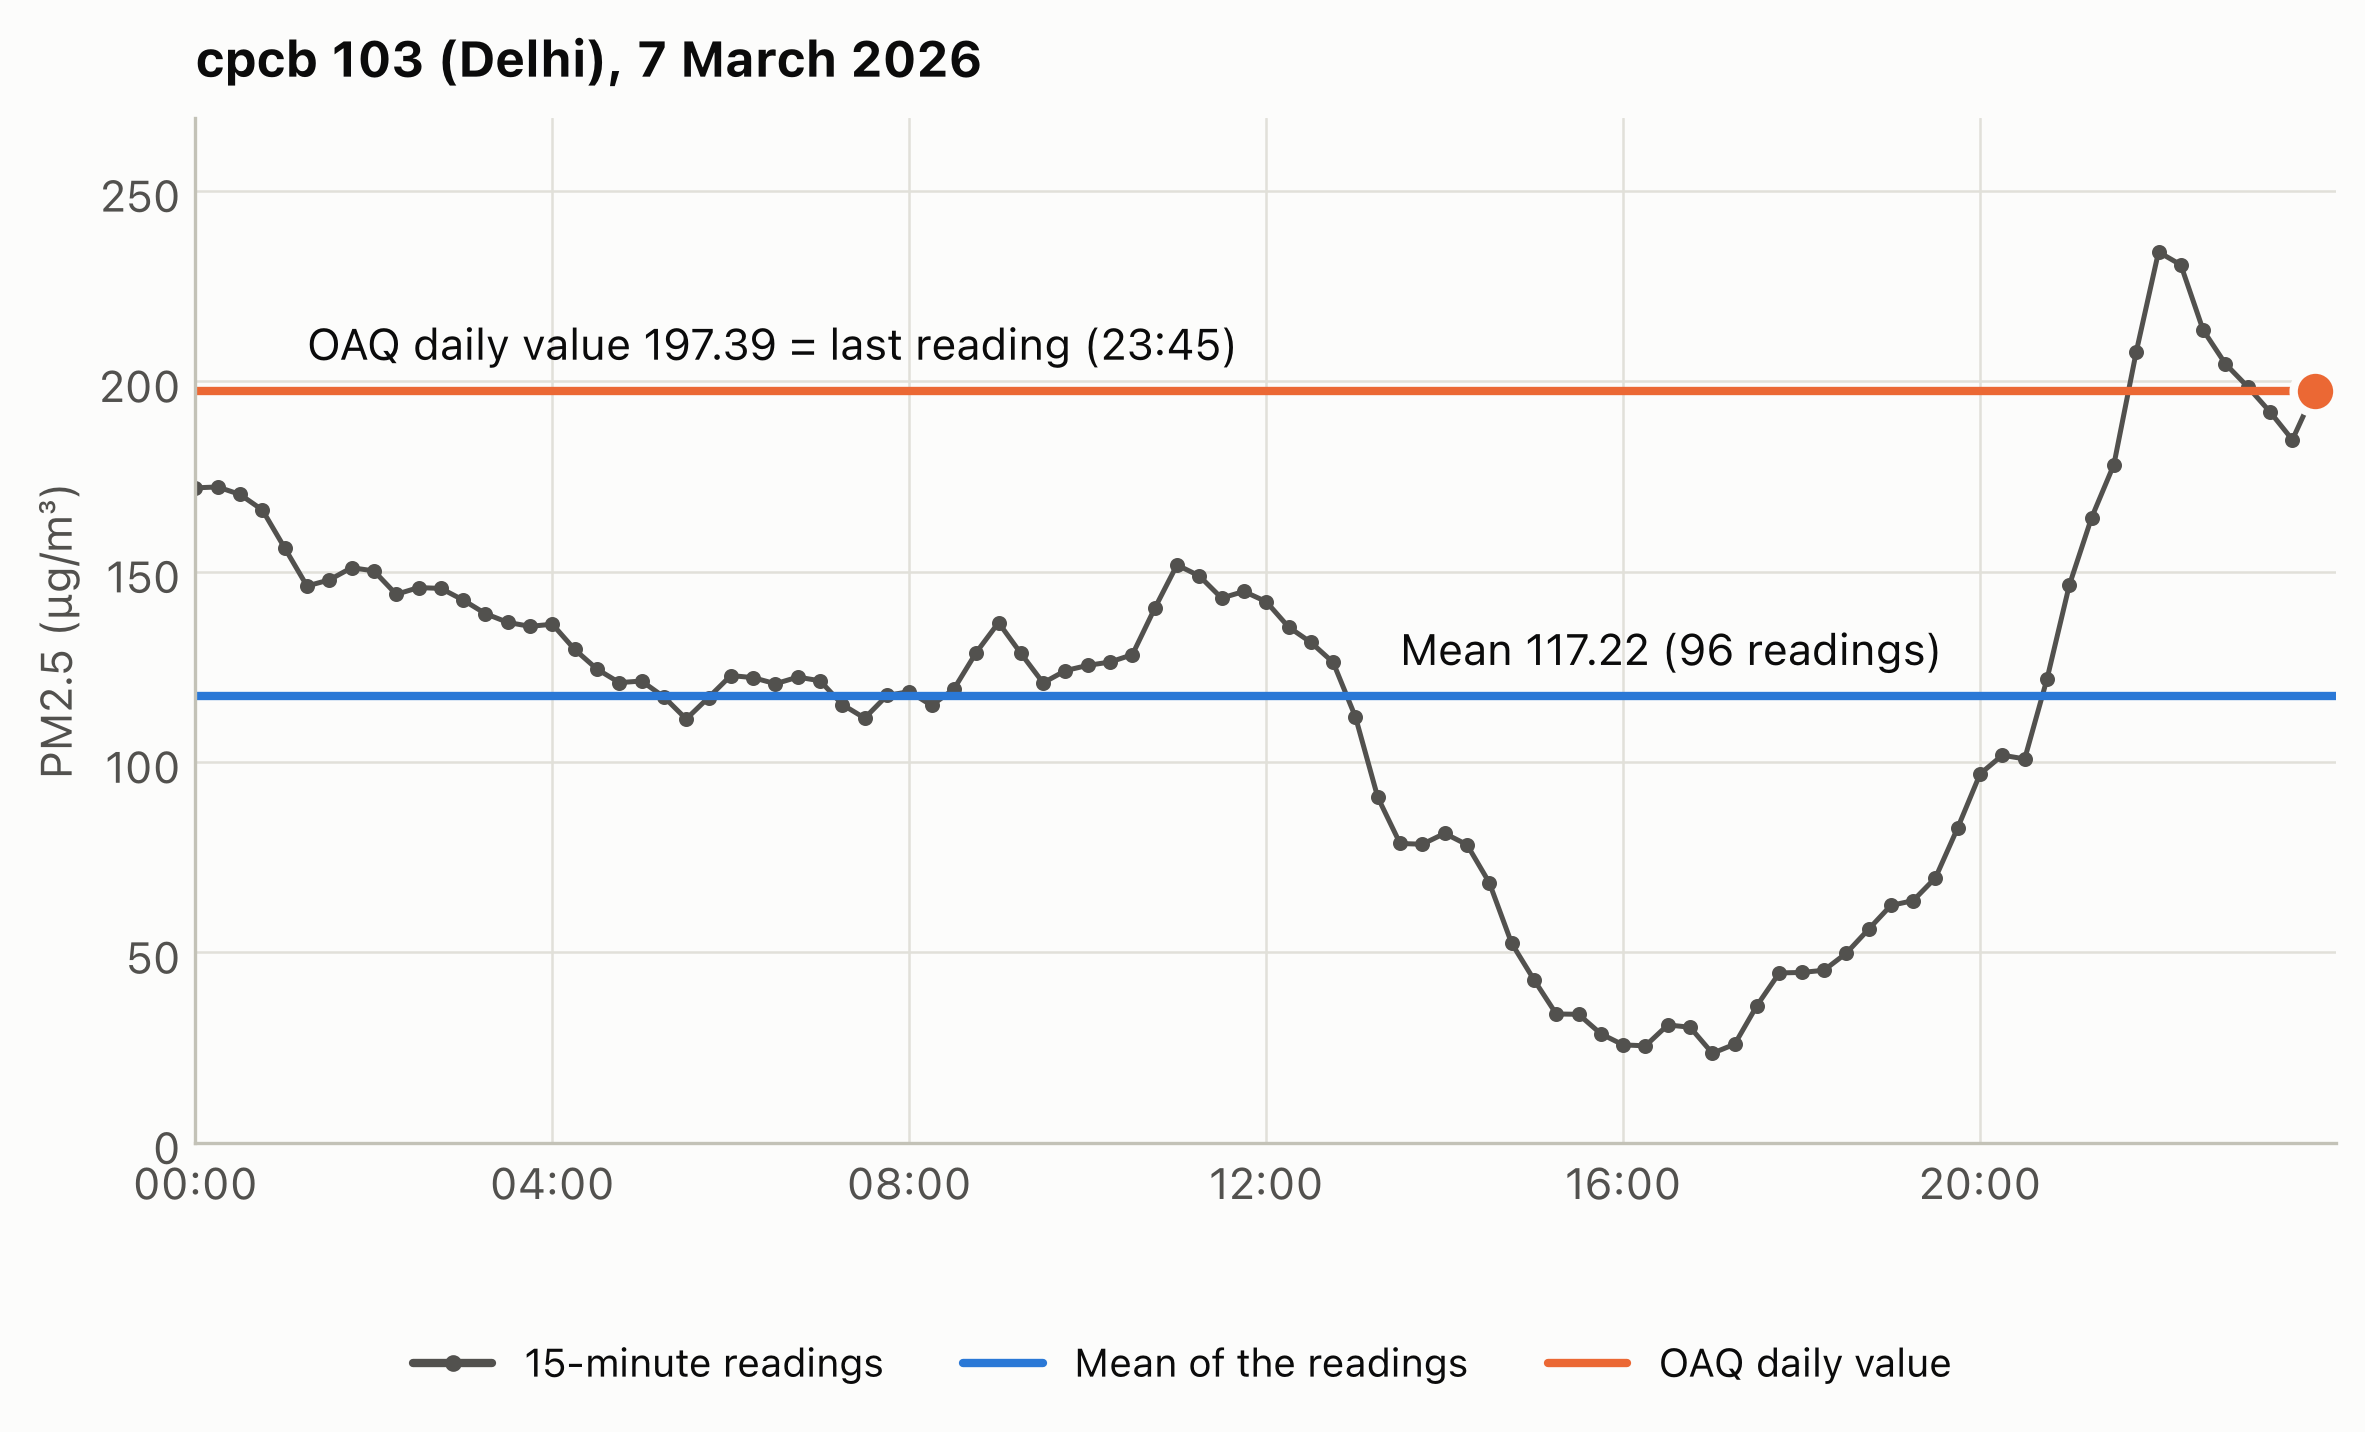

In [5]:
vy.plot_daily_record_day(
    oaq.readings("cpcb", "103", ["2026-03-07"]),
    check,
    title="cpcb 103 (Delhi), 7 March 2026",
)

The daily value is equal to the 23:45 reading. It is not the mean of the readings of the day, the maximum, or the mean of the last two readings. Two more days follow. On one of these days, the monthly file is also available. On the other day, the last readings of the day were very high.

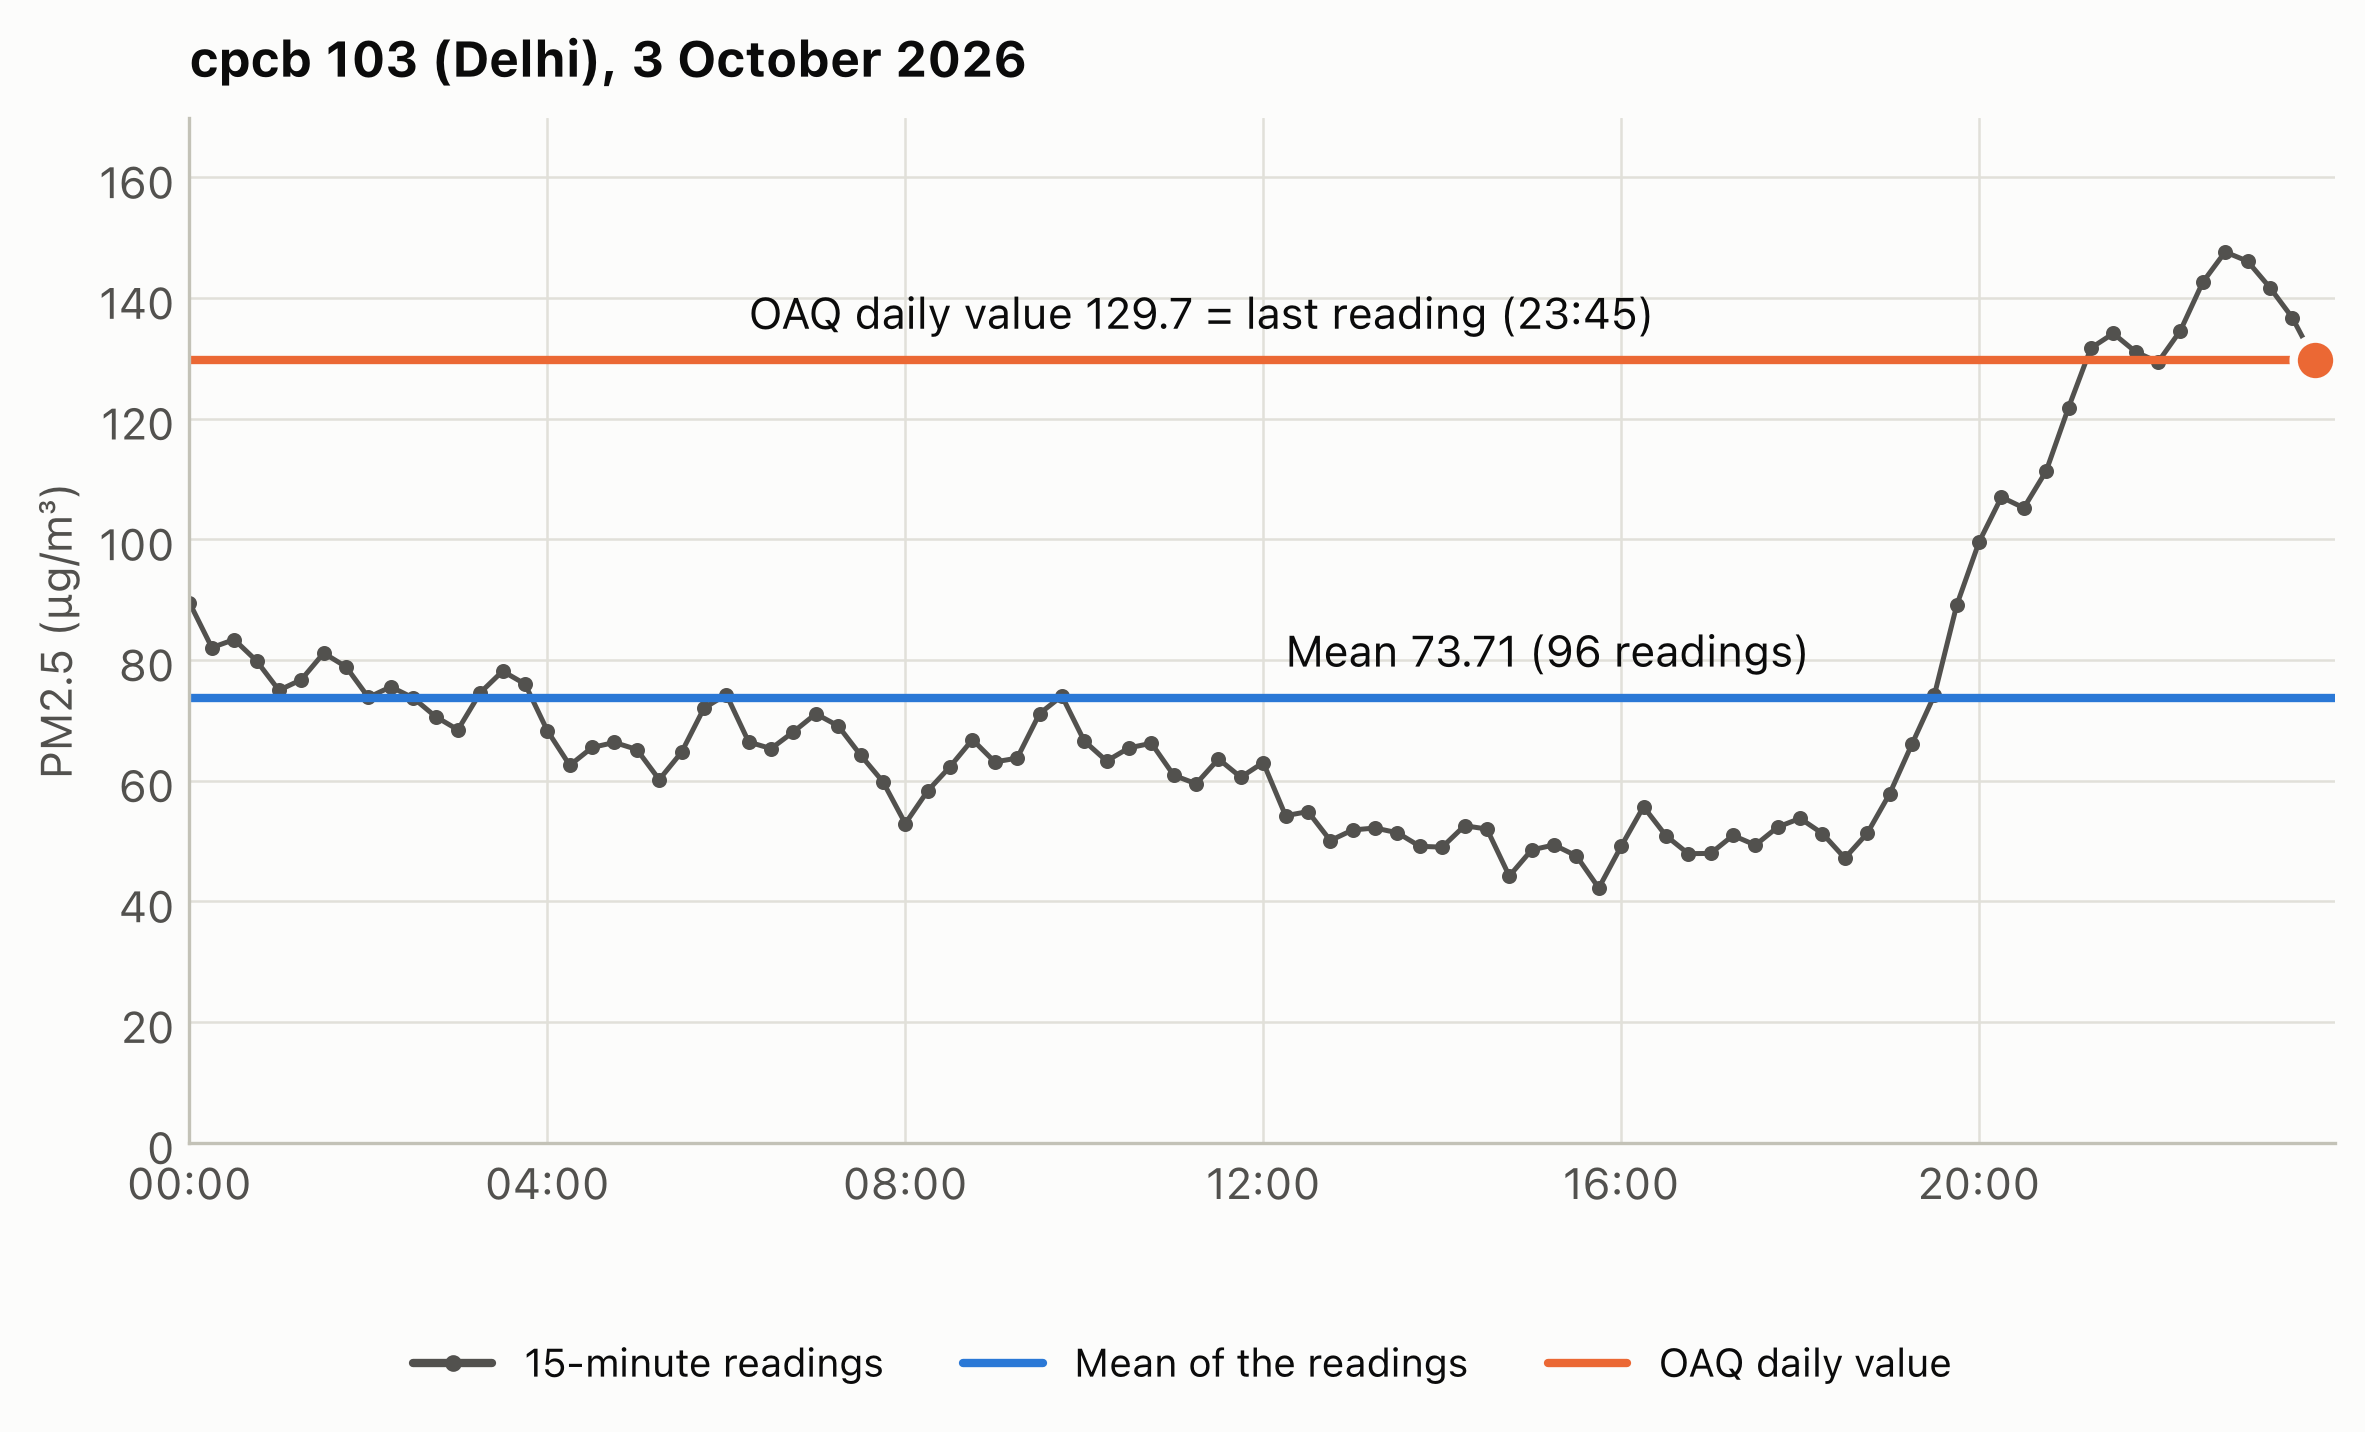

In [6]:
vy.plot_daily_record_day(
    oaq.readings("cpcb", "103", ["2026-10-03"]),
    oaq.check_daily_records("cpcb", "103", ["2026-10-03"]),
    title="cpcb 103 (Delhi), 3 October 2026",
)

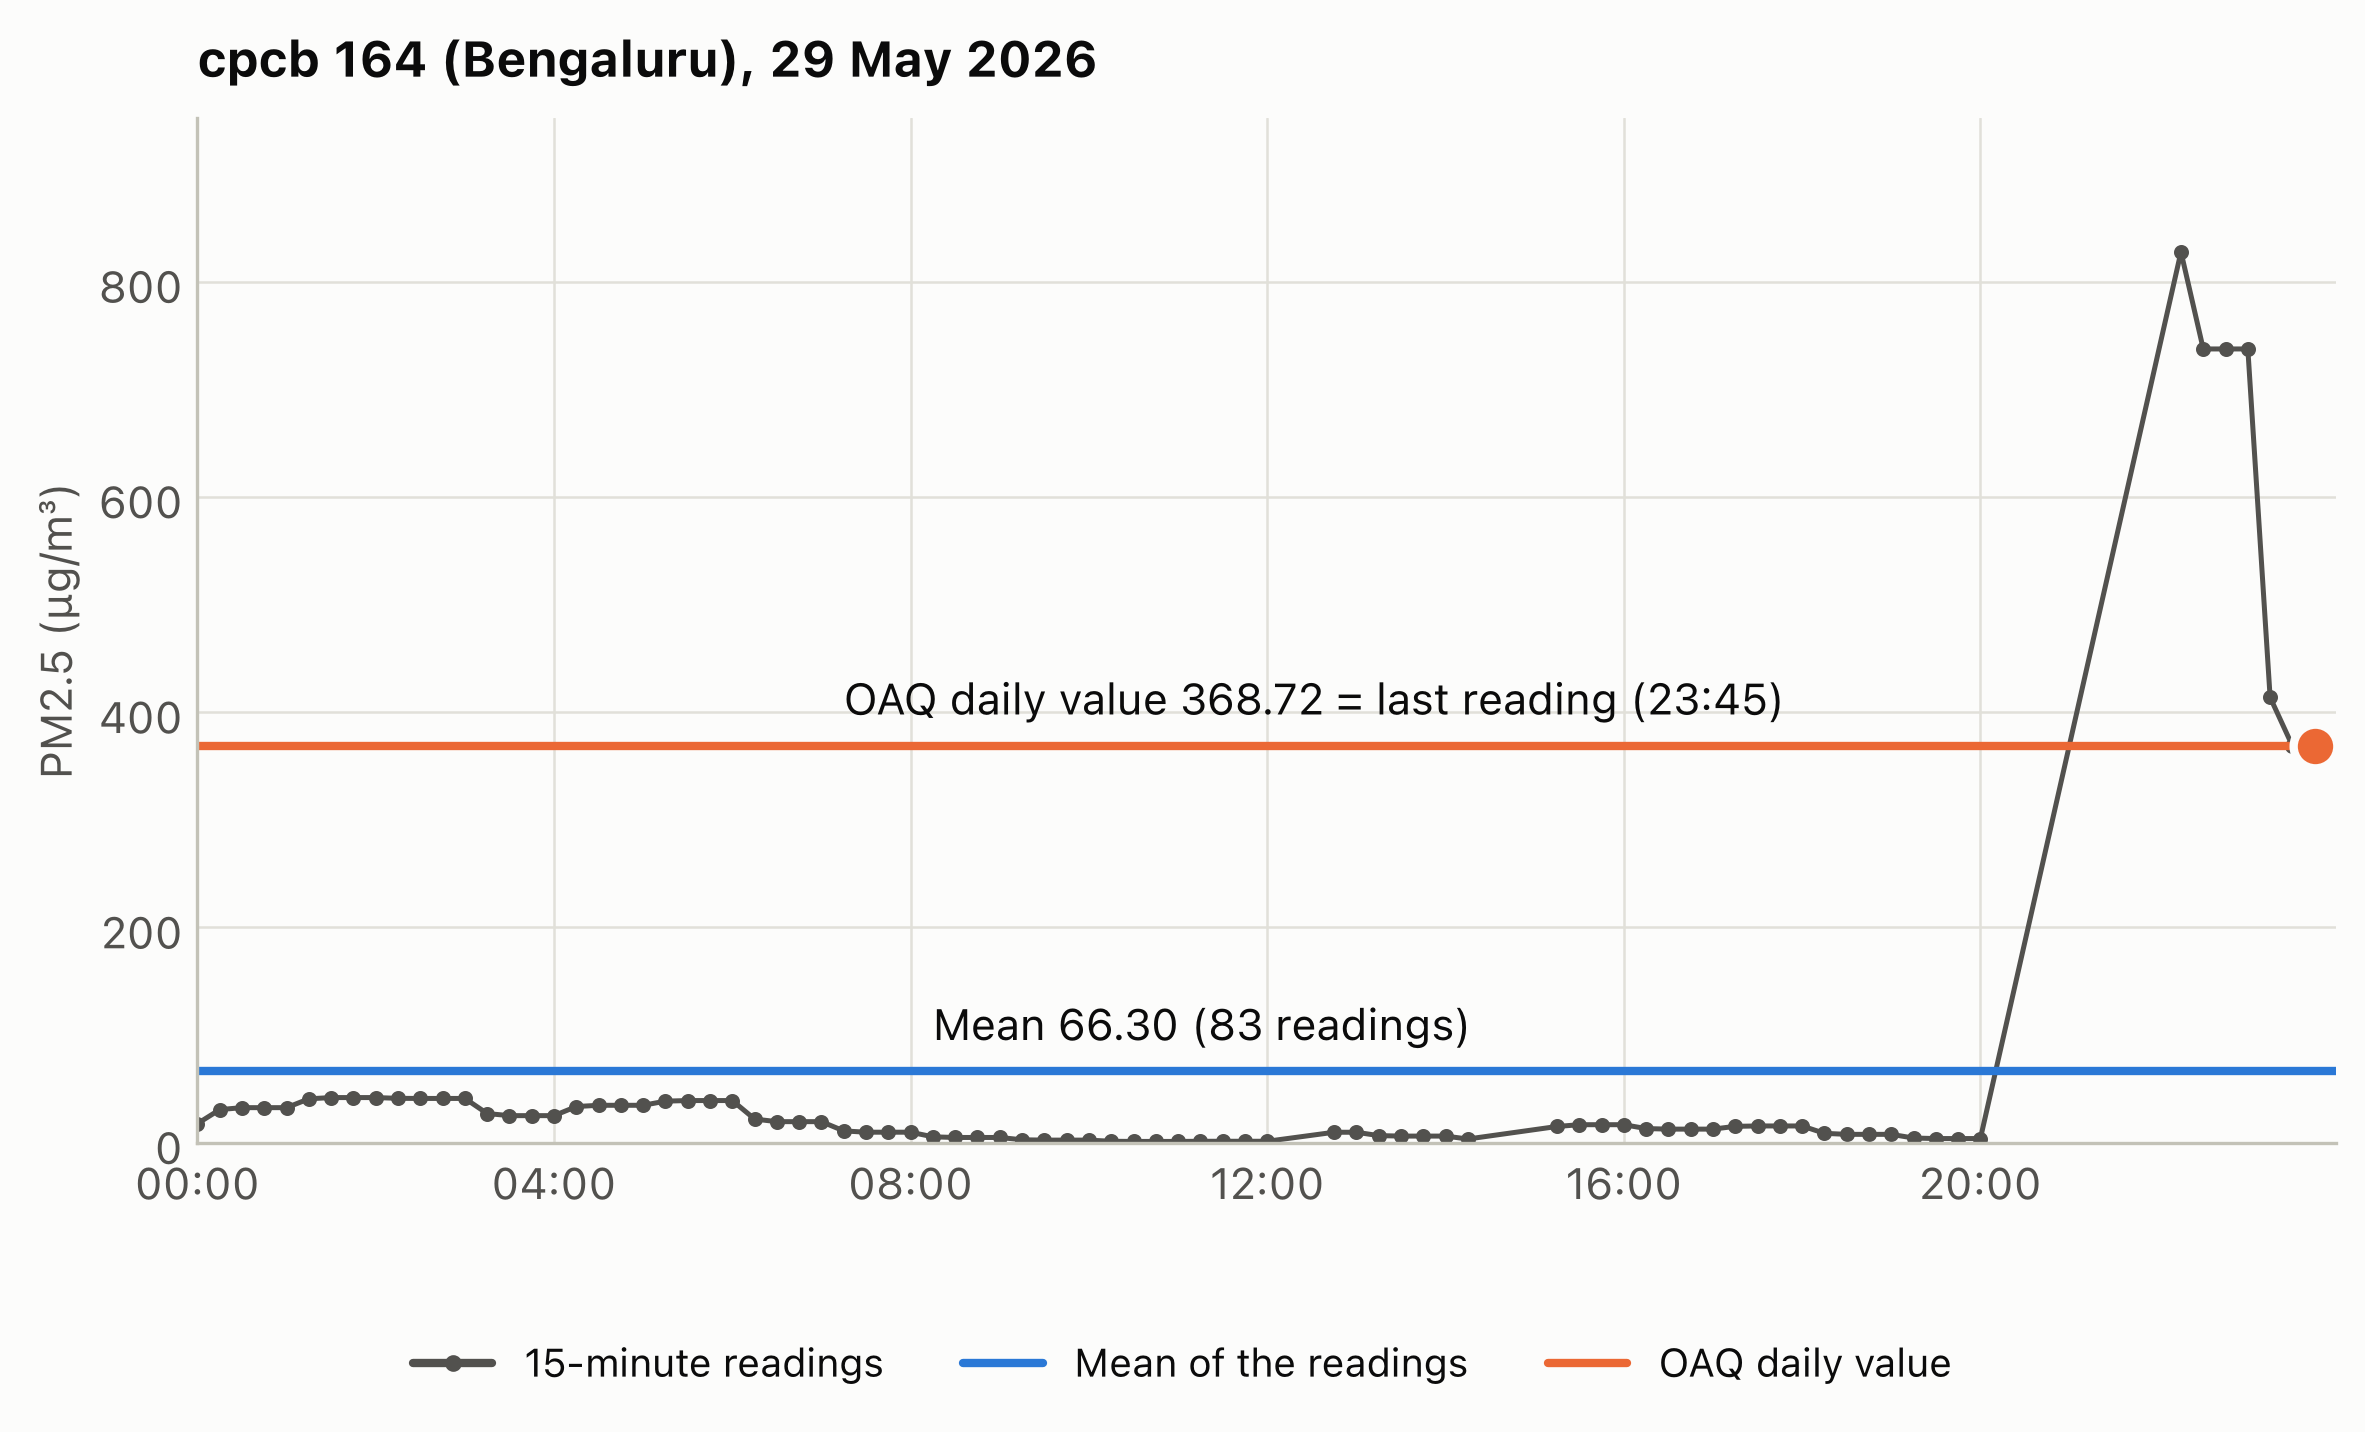

In [7]:
vy.plot_daily_record_day(
    oaq.readings("cpcb", "164", ["2026-05-29"]),
    oaq.check_daily_records("cpcb", "164", ["2026-05-29"]),
    title="cpcb 164 (Bengaluru), 29 May 2026",
)

## 2. Every day of six sensor-years

`audit_daily_records` examines each complete day of the specified sensors and years. It does not include today, because the values for today are not complete.

In [8]:
import pandas as pd

audit = pd.concat(
    [
        oaq.audit_daily_records([("cpcb", "164")], years=[2025, 2026]),
        oaq.audit_daily_records(
            [
                ("cpcb", "103"),
                ("airnet", "12036"),
                ("airnet", "12096"),
                ("aurassure", "14709"),
            ],
            years=[2026],
        ),
    ],
    ignore_index=True,
)
print(f"{len(audit)} days compared")
audit.groupby(["provider", "sensor_id"])["class"].value_counts().unstack(fill_value=0)

1159 days compared


class                both  last  mean  neither
provider  sensor_id                           
airnet    12036         0   158   106       10
          12096         0   121    68        6
aurassure 14709         1    75    57       61
cpcb      103           3   202    73        2
          164           9    97   109        1

`daily_record_summary` counts the days on which the difference between the mean and the last reading is more than 1. On these days, a value cannot accidentally agree with the two statistics. The function also finds when each sensor changed. It gives the last day on which the daily value is equal only to the mean. It also gives the first day on which the daily value is equal only to the last reading.

In [9]:
vy.daily_record_summary(audit)

,provider,sensor_id,year,days,clear_days,mean,last,neither,last_mean_day,first_last_day
0,airnet,12036,2026,274,223,85,131,7,2026-02-26,2026-03-01
1,airnet,12096,2026,195,161,59,97,5,2026-02-27,2026-03-02
2,aurassure,14709,2026,194,175,53,68,54,2026-02-27,2026-02-28
3,cpcb,103,2026,280,273,73,198,2,2026-02-27,2026-03-01
4,cpcb,164,2025,69,40,39,0,1,2025-12-31,None
5,cpcb,164,2026,147,88,29,59,0,2026-02-14,2026-03-04


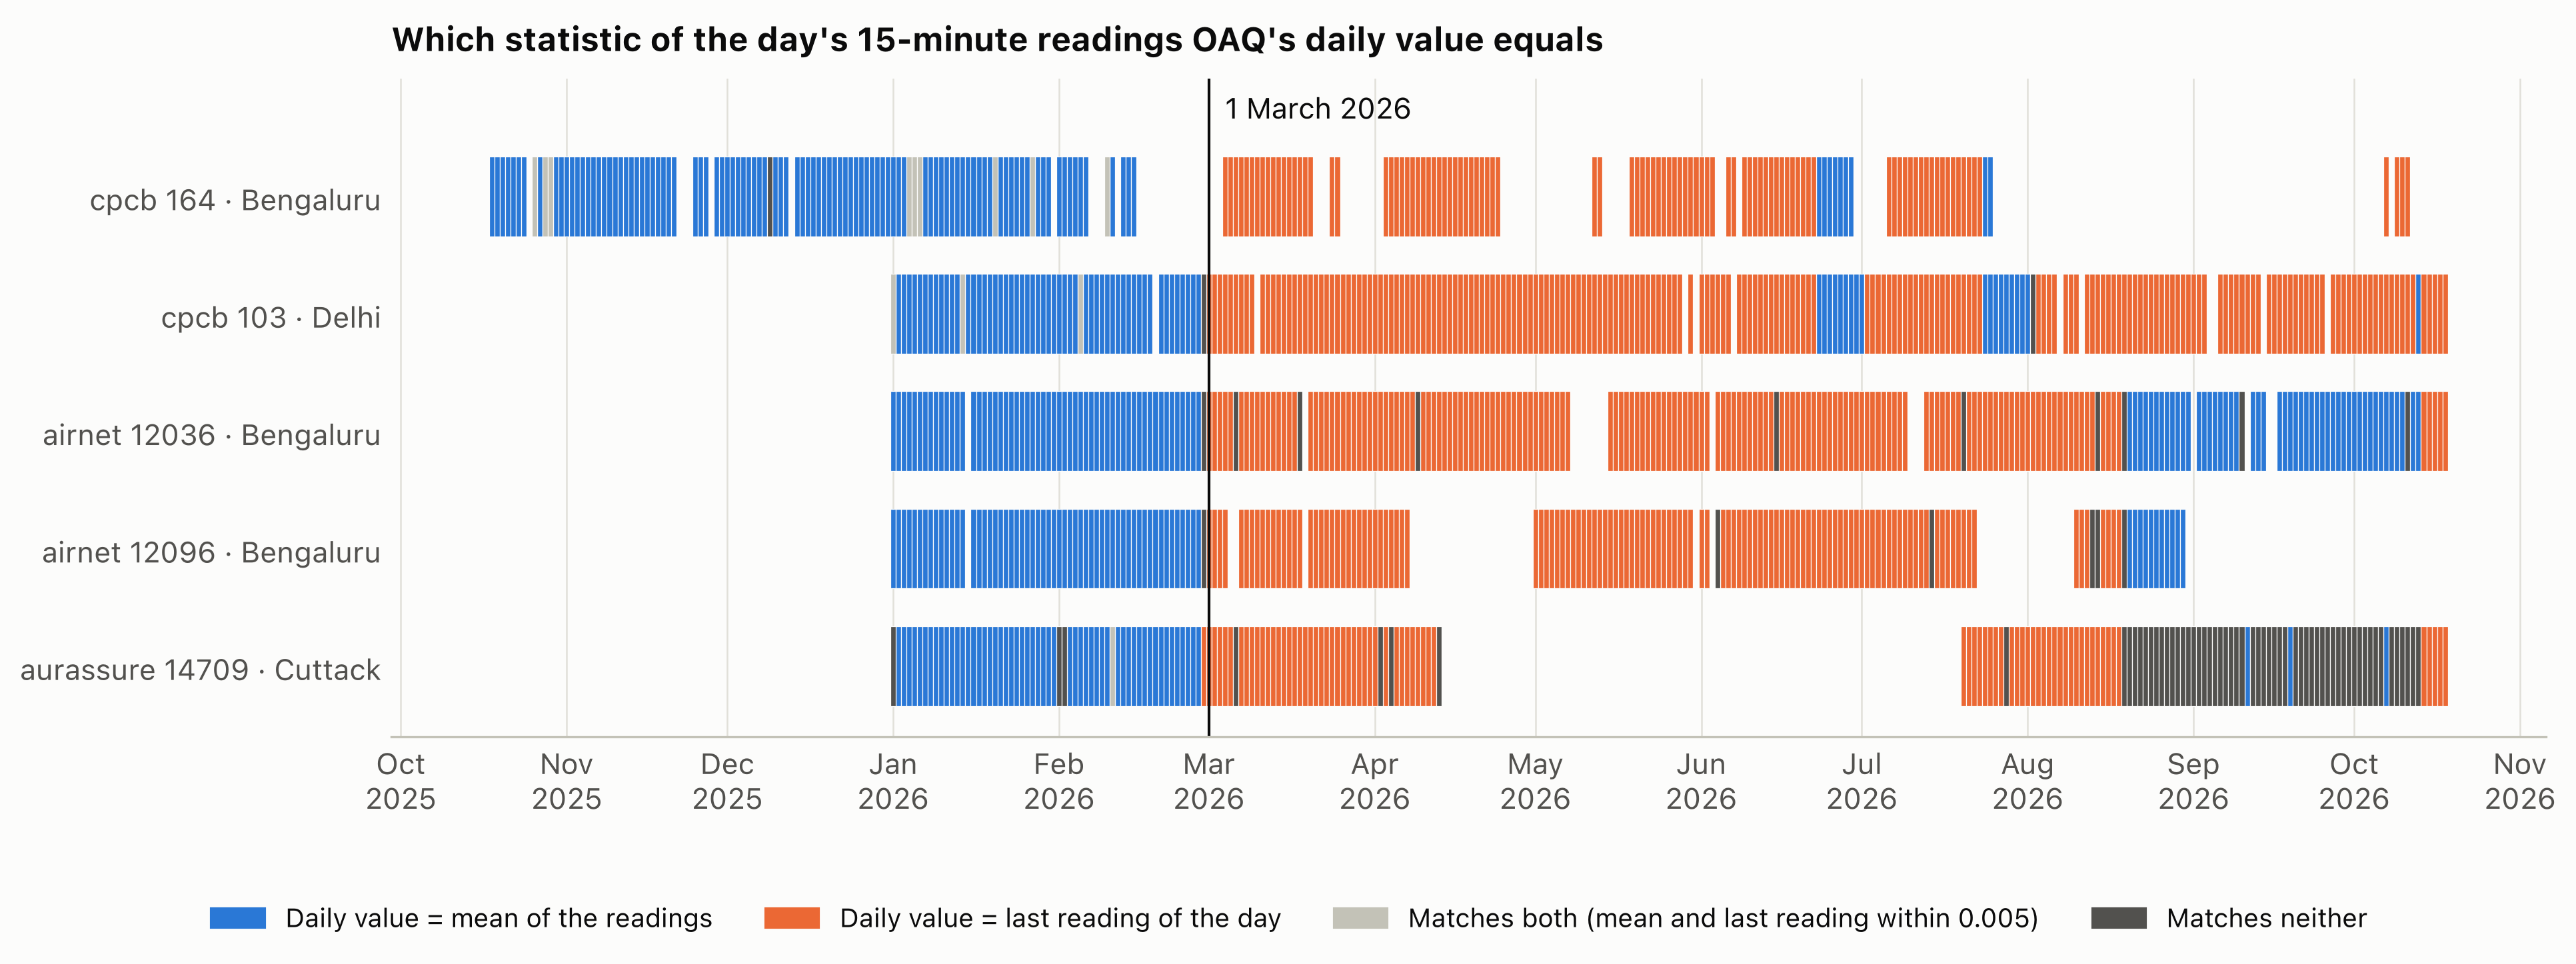

In [10]:
vy.plot_daily_record_timeline(audit, change=CHANGE, labels=LABELS)

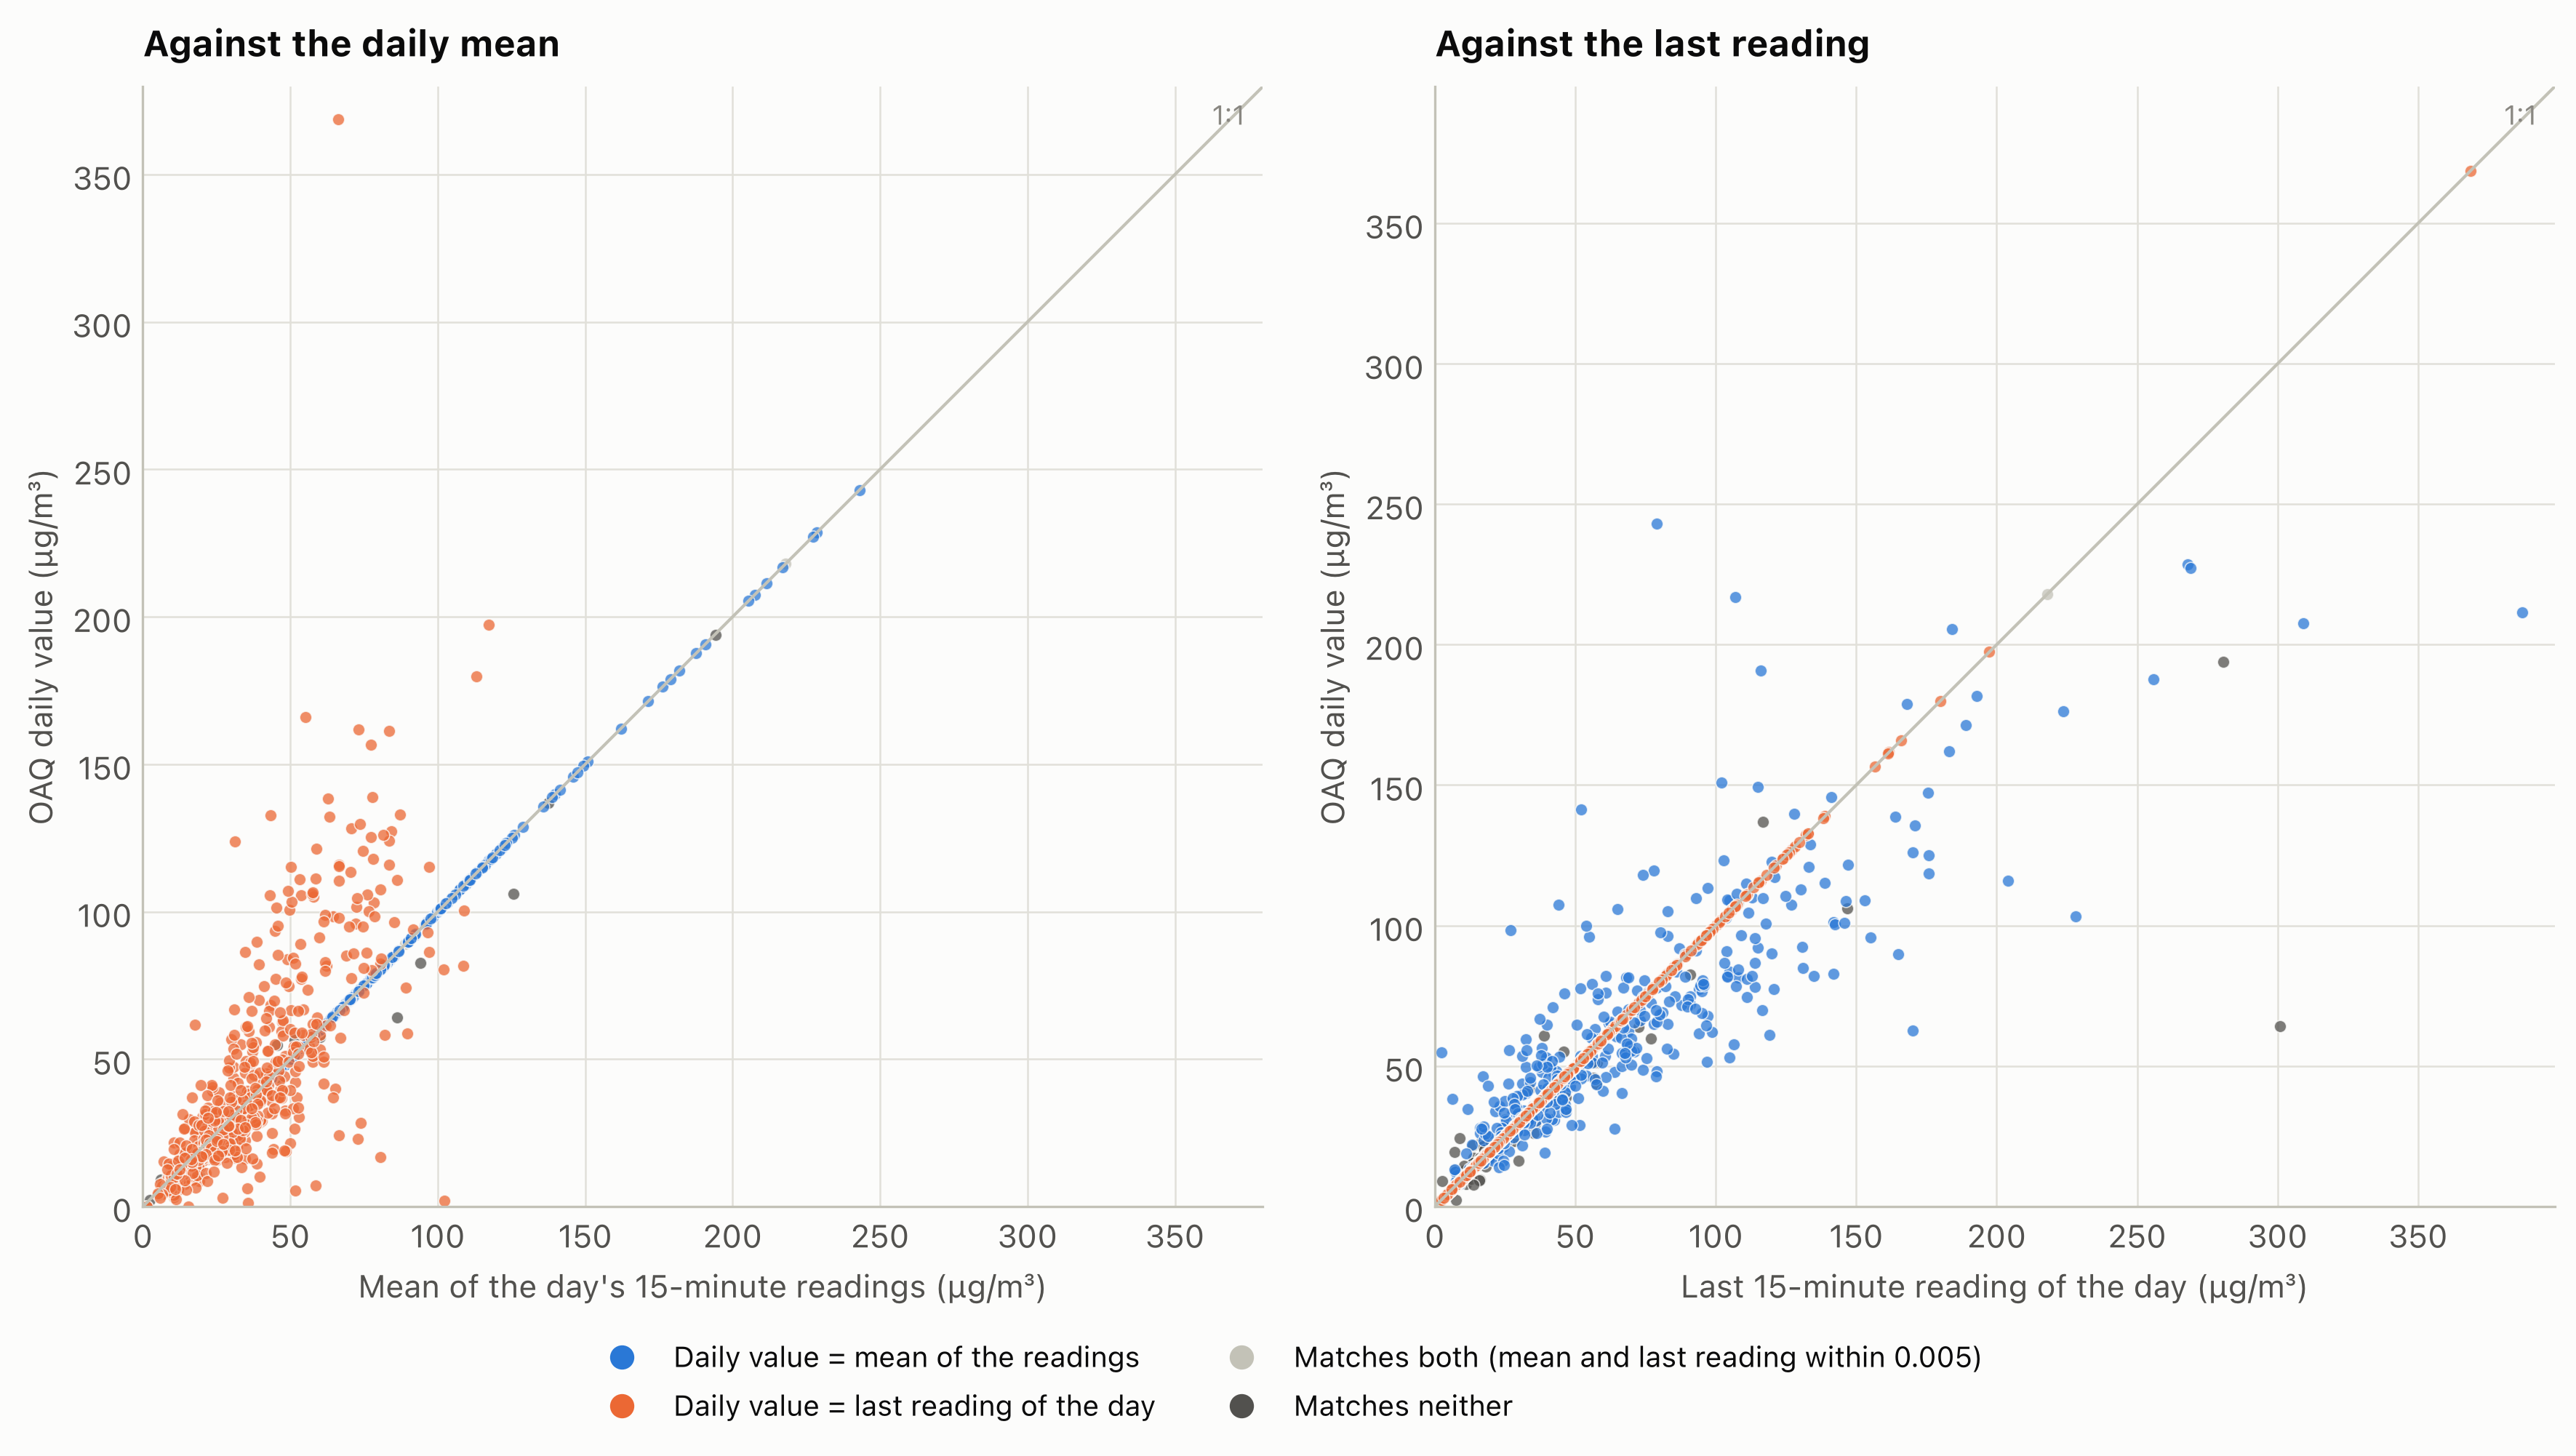

In [11]:
vy.plot_daily_record_scatter(audit)

Days with a daily value equal to the mean (blue) are on the 1:1 line on the left. Days with a daily value equal to the last reading (orange) are on the 1:1 line on the right.

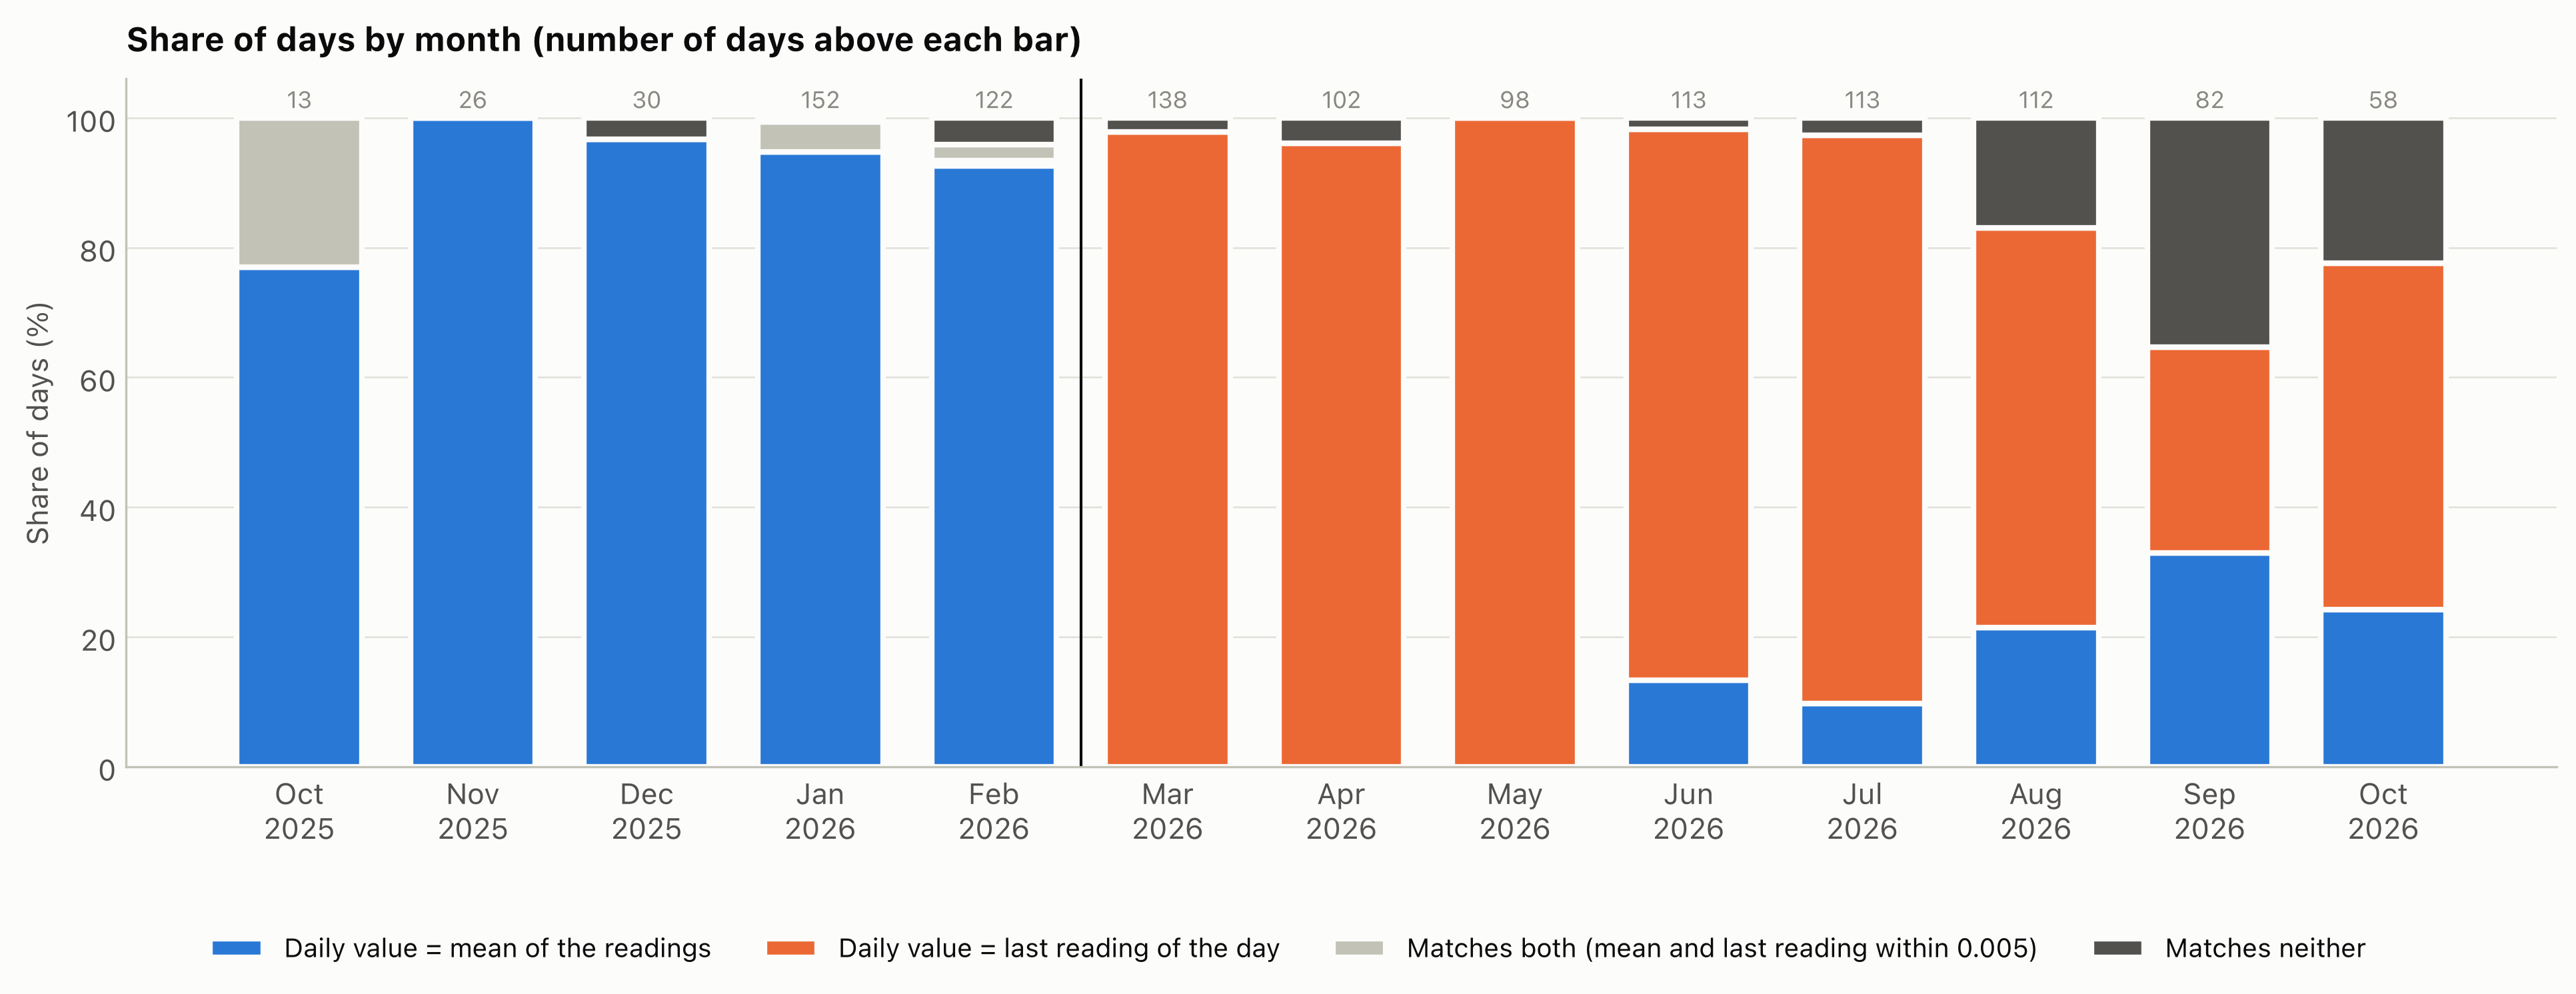

In [12]:
vy.plot_daily_record_share(audit, change=CHANGE)

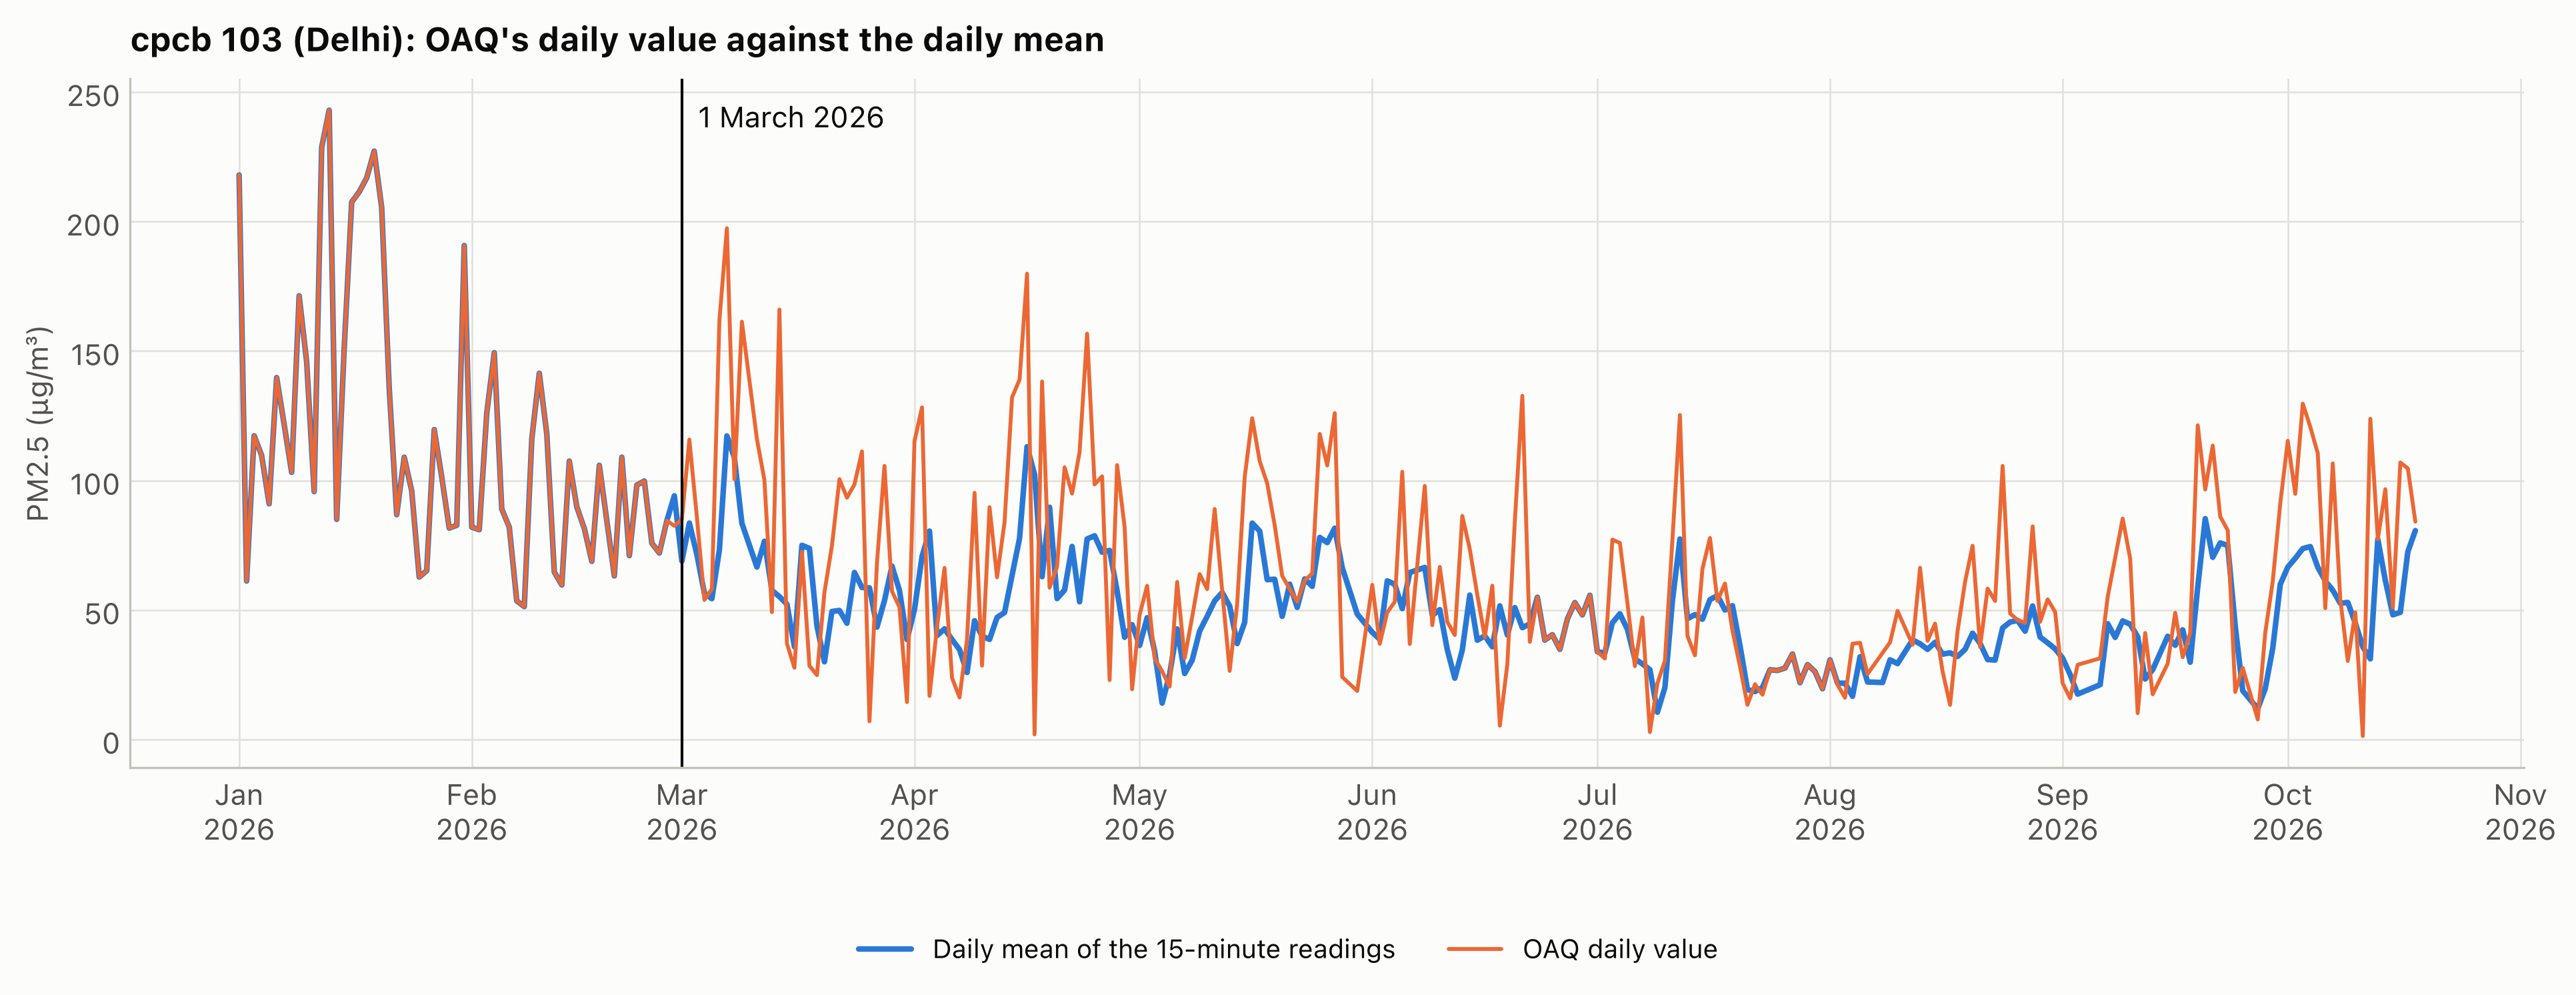

In [13]:
vy.plot_daily_record_series(
    audit,
    "103",
    change=CHANGE,
    title="cpcb 103 (Delhi): OAQ's daily value against the daily mean",
)

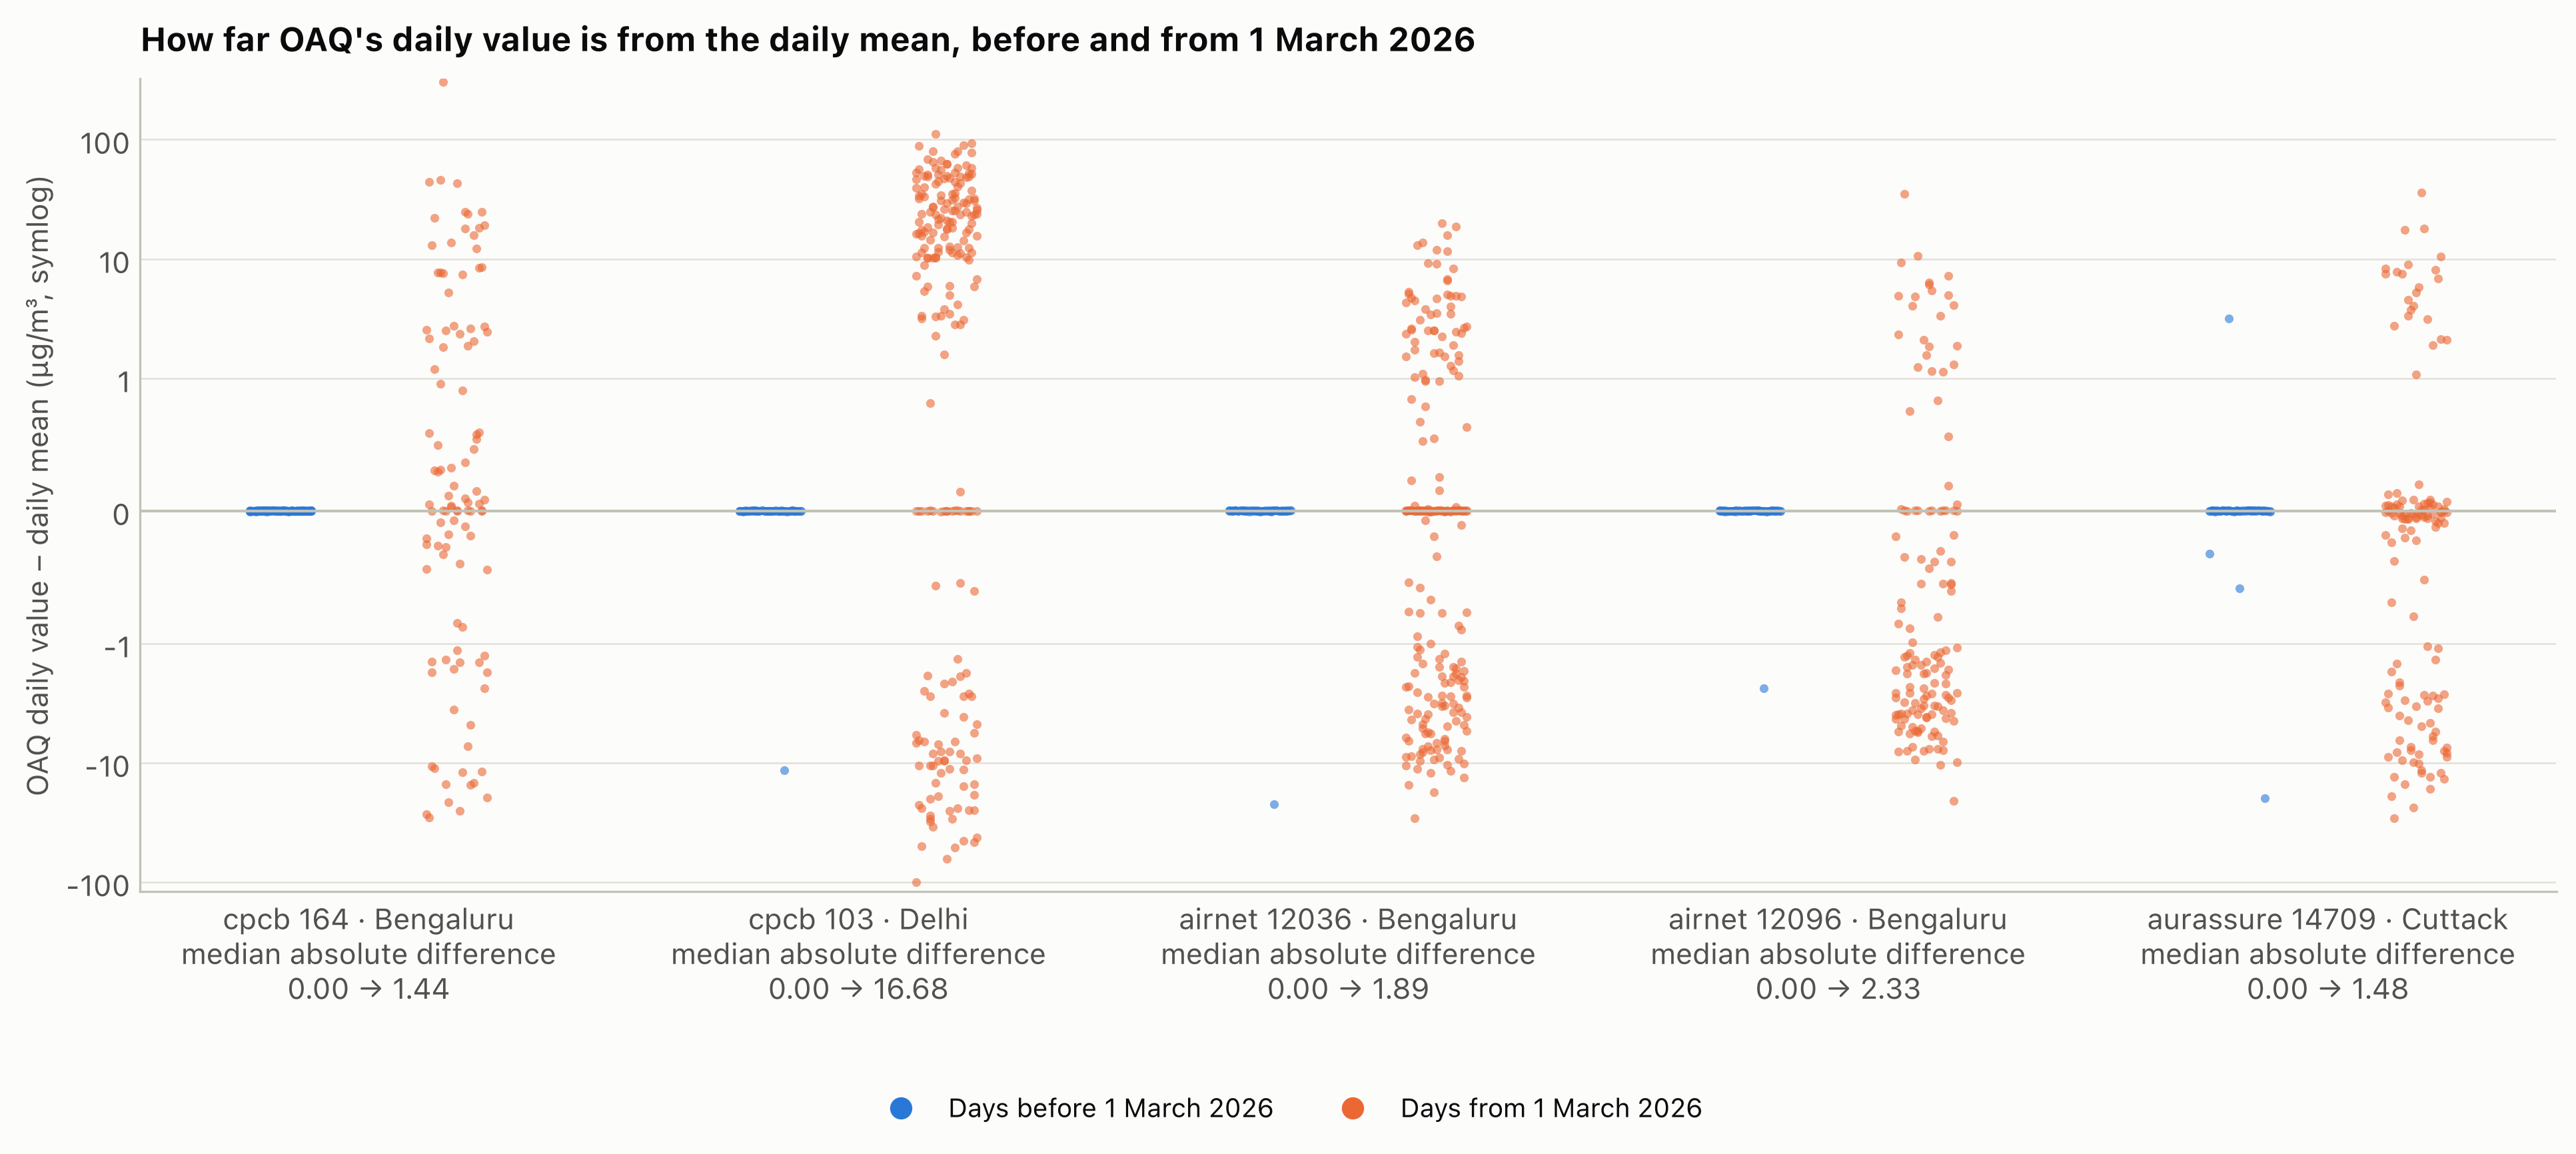

In [14]:
vy.plot_daily_record_difference(audit, CHANGE, labels=LABELS)

## 3. Other explanations

This section counts the days on which the daily value is equal to each statistic of the readings. The statistics are the mean, the last reading, the maximum and the median. The other statistics are the mean of the last 2 readings and the mean of the last 4 readings. These two statistics are a running mean at the end of the day.

In [15]:
audit.groupby(["provider", "sensor_id"])[
    [f"record_is_{s}" for s in vy.oaq_records.RECORD_STATISTICS]
].sum()

record_is_mean  record_is_last  record_is_max  \
provider  sensor_id                                                  
airnet    12036                 106             158              2   
          12096                  68             121              0   
aurassure 14709                  58              76              0   
cpcb      103                    76             205             25   
          164                   118             106             13   

                     record_is_median  record_is_last_2_mean  \
provider  sensor_id                                            
airnet    12036                     7                      7   
          12096                     5                      5   
aurassure 14709                     0                      2   
cpcb      103                      10                      8   
          164                      17                     60   

                     record_is_last_4_mean  
provider  sensor_id                         
airnet    12036                          6  
          12096                          4  
aurassure 14709                          0  
cpcb      103                           24  
          164                           32

## Notes

- The analysis uses only `pm25`, and five sensors from three providers.
- Some daily values do not agree with the mean or with the last reading. Most of these values are for Aurassure 14709 from August 2026. We do not know what these values are.
- For `cpcb` 103 and `cpcb` 164, `monthly_2026_03.json` returns HTTP 404. But `annual_2026.json` has the data for March. Also, for `cpcb` 164, some days of the annual file are missing from the monthly file.
- For `cpcb` 164, `annual_2026.json` has daily values for some days on which the daily files have no readings. The comparison does not include these days.
- The R package has the same functions: `oaq_audit_daily_records()`, `daily_record_summary()` and `plot_daily_record_*()`. The R article *OAQ daily values* does this analysis again.